# Unsupervised Results Visualization

This notebook visualizes model comparison metrics from `unsupervised_results.csv`.

It focuses on:
- mean performance by model
- per-fold variability
- NaN coverage by metric (to explain non-applicable metrics)

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

plt.style.use('seaborn-v0_8-whitegrid')

In [22]:
results_path = '../data/steem_collection/unsupervised_results.csv'
df = pd.read_csv(results_path)

df.head()

,model,fold,accuracy,precision,recall,f1,silhouette,anomaly_rate,n_clusters,noise_ratio
0,IsolationForest,1,0.695652,0.000000,0.000000,0.000000,NaN,0.066351,NaN,NaN
1,OneClassSVM,1,0.304348,0.304348,1.000000,0.466667,NaN,1.000000,NaN,NaN
2,LocalOutlierFactor,1,0.630435,0.285714,0.142857,0.190476,NaN,0.170616,NaN,NaN
3,IsolationForest,2,0.656250,0.500000,0.272727,0.352941,NaN,0.255924,NaN,NaN
4,OneClassSVM,2,0.625000,0.473684,0.818182,0.600000,NaN,0.606635,NaN,NaN


In [23]:
mean_df = df[df['fold'].astype(str) == 'mean'].copy()
fold_df = df[df['fold'].astype(str) != 'mean'].copy()

numeric_cols = ['silhouette', 'anomaly_rate', 'n_clusters', 'noise_ratio']
mean_df[['model'] + numeric_cols].sort_values('anomaly_rate', ascending=False)

,model,silhouette,anomaly_rate,n_clusters,noise_ratio
30,DBSCAN-noise-as-bot,NaN,1.000000,0.0,1.0
35,OneClassSVM,NaN,0.699188,NaN,NaN
31,GaussianMixture-2,0.042910,0.357725,2.0,0.0
33,KMeans-2,0.087512,0.326436,2.0,0.0
34,LocalOutlierFactor,NaN,0.182185,NaN,NaN
32,IsolationForest,NaN,0.153712,NaN,NaN


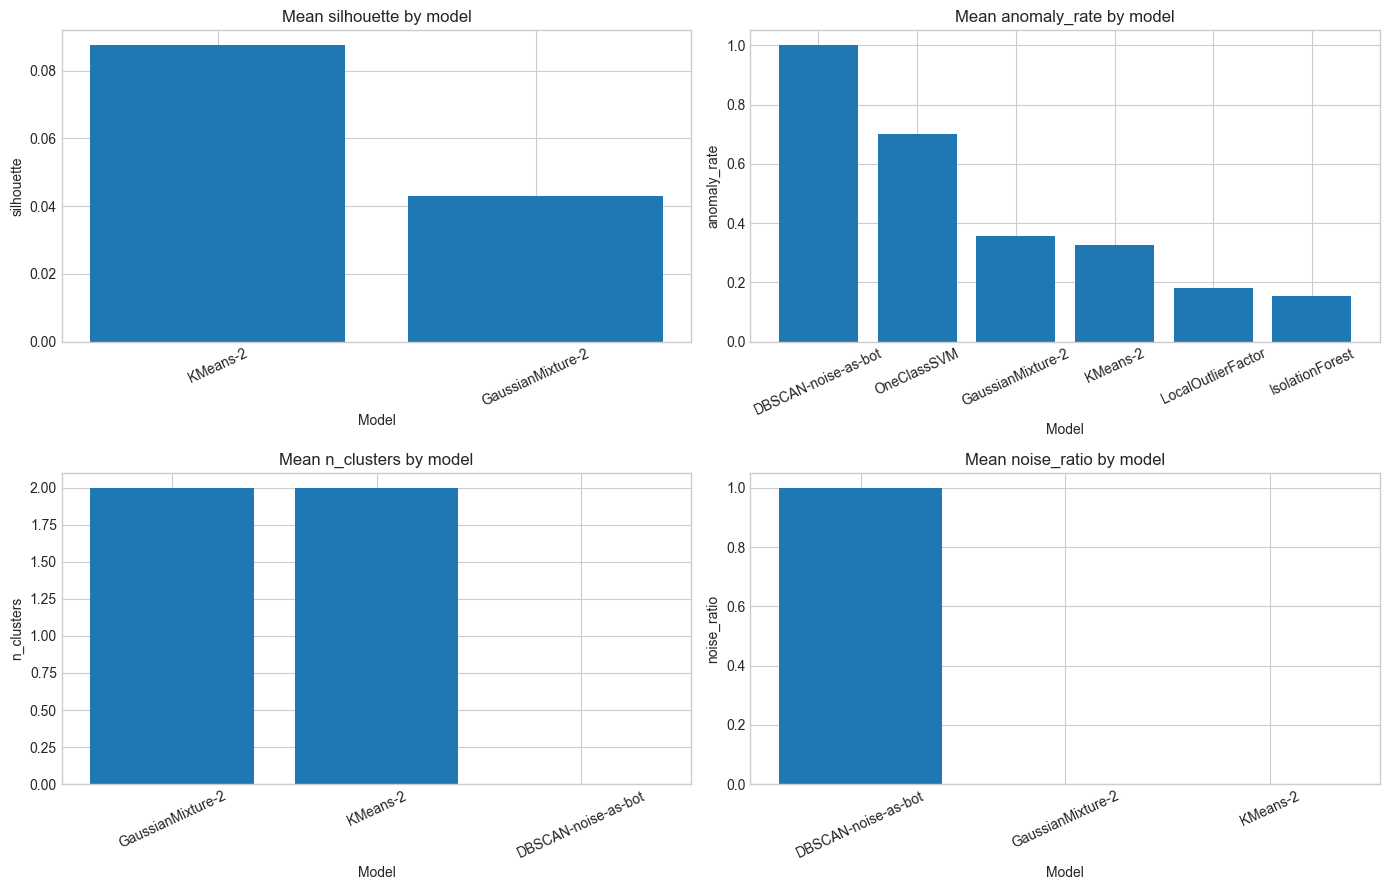

In [24]:
# 1) Mean metric comparison by model
plot_cols = ['silhouette', 'anomaly_rate', 'n_clusters', 'noise_ratio']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for i, col in enumerate(plot_cols):
    ax = axes[i]
    data = mean_df[['model', col]].dropna().sort_values(col, ascending=False)
    ax.bar(data['model'], data[col])
    ax.set_title(f'Mean {col} by model')
    ax.set_xlabel('Model')
    ax.set_ylabel(col)
    ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

C:\Users\nonoc\AppData\Local\Temp\ipykernel_7940\112097294.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(grouped, labels=models, showmeans=True)


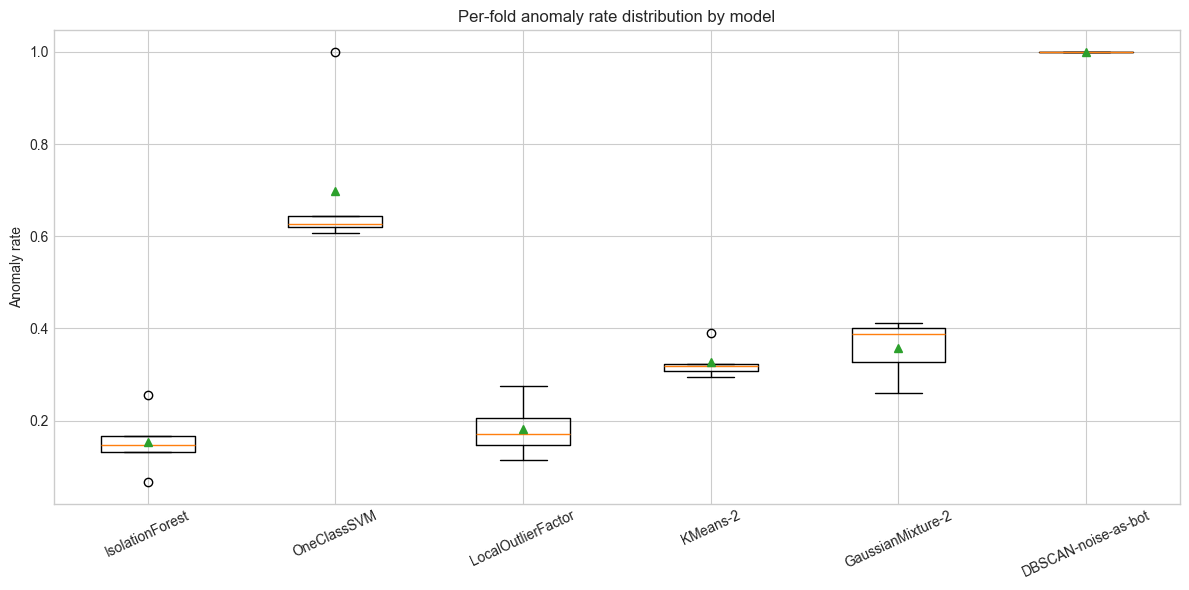

In [25]:
# 2) Per-fold anomaly rate variability
if not fold_df.empty:
    fig, ax = plt.subplots(figsize=(12, 6))
    models = fold_df['model'].unique().tolist()
    grouped = [fold_df.loc[fold_df['model'] == m, 'anomaly_rate'].dropna().values for m in models]
    ax.boxplot(grouped, labels=models, showmeans=True)
    ax.set_title('Per-fold anomaly rate distribution by model')
    ax.set_ylabel('Anomaly rate')
    ax.tick_params(axis='x', rotation=25)
    plt.tight_layout()
    plt.show()
else:
    print('No fold-level rows available (only mean rows found).')

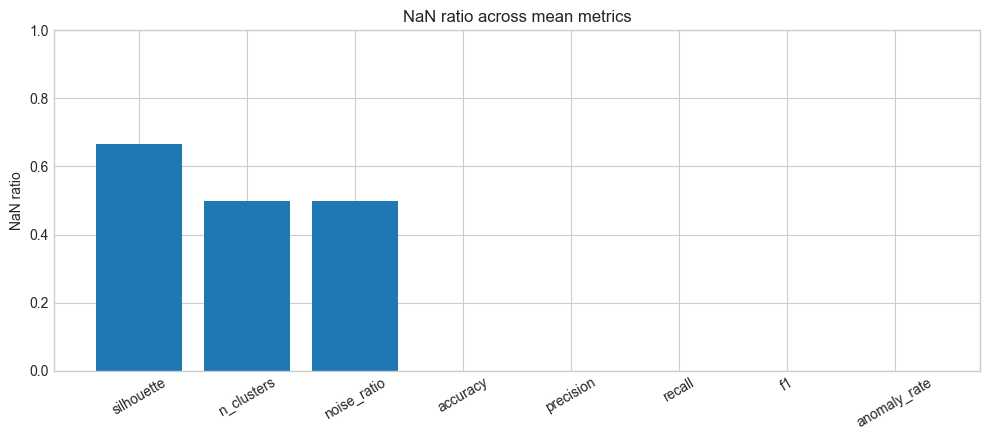

silhouette      0.666667
n_clusters      0.500000
noise_ratio     0.500000
accuracy        0.000000
precision       0.000000
recall          0.000000
f1              0.000000
anomaly_rate    0.000000
dtype: float64

In [26]:
# 3) NaN coverage by metric (helps explain non-applicable metrics)
metric_cols = ['accuracy', 'precision', 'recall', 'f1', 'silhouette', 'anomaly_rate', 'n_clusters', 'noise_ratio']
nan_ratio = mean_df[metric_cols].isna().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(nan_ratio.index, nan_ratio.values)
ax.set_title('NaN ratio across mean metrics')
ax.set_ylabel('NaN ratio')
ax.set_ylim(0, 1.0)
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

nan_ratio

In [27]:
# 4) Compact model summary table
summary = mean_df[['model', 'silhouette', 'anomaly_rate', 'n_clusters', 'noise_ratio']].copy()
summary = summary.sort_values(['silhouette', 'anomaly_rate'], ascending=[False, True])
summary.reset_index(drop=True)

,model,silhouette,anomaly_rate,n_clusters,noise_ratio
0,KMeans-2,0.087512,0.326436,2.0,0.0
1,GaussianMixture-2,0.042910,0.357725,2.0,0.0
2,IsolationForest,NaN,0.153712,NaN,NaN
3,LocalOutlierFactor,NaN,0.182185,NaN,NaN
4,OneClassSVM,NaN,0.699188,NaN,NaN
5,DBSCAN-noise-as-bot,NaN,1.000000,0.0,1.0


## Clustering/Segmentation View for Each Model

This section projects the feature space to 2D with PCA and visualizes how each model segments accounts.

- KMeans / GaussianMixture / DBSCAN: shown as cluster labels.
- IsolationForest / OneClassSVM / LocalOutlierFactor: shown as inlier (`+1`) vs outlier (`-1`) regions.

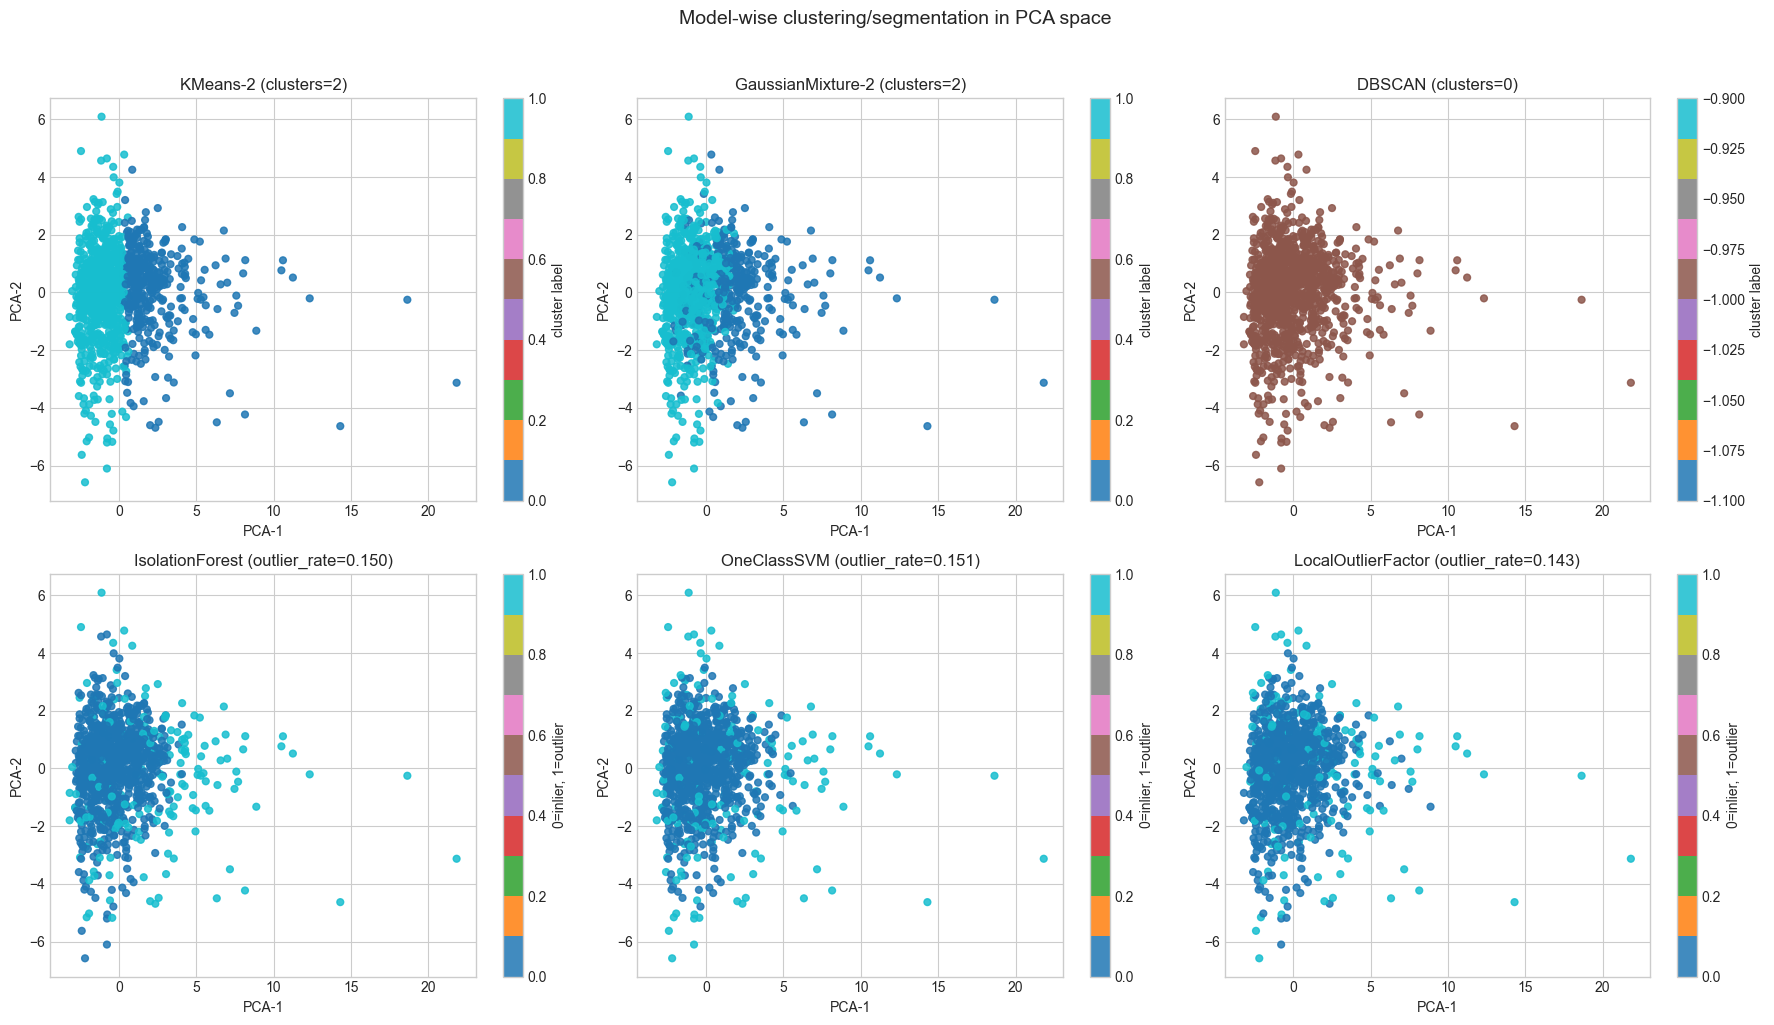

In [28]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

features_path = '../data/steem_collection/features.csv'
features_df = pd.read_csv(features_path)

# Keep only numeric feature columns and remove infinities/NaNs.
X_df = features_df.select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan).fillna(0.0)

if X_df.empty:
    raise ValueError('No numeric features found in features.csv for clustering plots.')

X = X_df.to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X)
X_2d = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

models = {
    'KMeans-2': KMeans(n_clusters=2, random_state=42, n_init=20),
    'GaussianMixture-2': GaussianMixture(n_components=2, covariance_type='full', random_state=42),
    'DBSCAN': DBSCAN(eps=1.2, min_samples=8),
    'IsolationForest': IsolationForest(n_estimators=300, contamination=0.15, random_state=42, n_jobs=-1),
    'OneClassSVM': OneClassSVM(kernel='rbf', gamma='scale', nu=0.15),
    'LocalOutlierFactor': LocalOutlierFactor(n_neighbors=35, contamination=0.15, novelty=True),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_scaled)

    if name in ('KMeans-2', 'GaussianMixture-2', 'DBSCAN'):
        labels = model.predict(X_scaled) if hasattr(model, 'predict') else model.fit_predict(X_scaled)
        title_suffix = f'clusters={len(set(labels)) - (1 if -1 in labels else 0)}'
    else:
        raw_pred = model.predict(X_scaled)  # +1 inlier, -1 outlier
        labels = np.where(raw_pred == -1, 1, 0)  # 1=outlier, 0=inlier
        title_suffix = f'outlier_rate={labels.mean():.3f}'

    scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', s=24, alpha=0.85)
    ax.set_title(f'{name} ({title_suffix})')
    ax.set_xlabel('PCA-1')
    ax.set_ylabel('PCA-2')

    cbar = plt.colorbar(scatter, ax=ax)
    if name in ('IsolationForest', 'OneClassSVM', 'LocalOutlierFactor'):
        cbar.set_label('0=inlier, 1=outlier')
    else:
        cbar.set_label('cluster label')

plt.suptitle('Model-wise clustering/segmentation in PCA space', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## Feature-Level Clustering Showcase (KMeans First)

This section focuses on **KMeans** only so you can inspect feature-level clustering clearly before comparing other models.

- Rows: KMeans cluster labels
- Columns: features
- Values: mean standardized feature value ($z$-score)

Interpretation:
- Red ($z > 0$): feature is above dataset average for that cluster
- Blue ($z < 0$): feature is below dataset average for that cluster

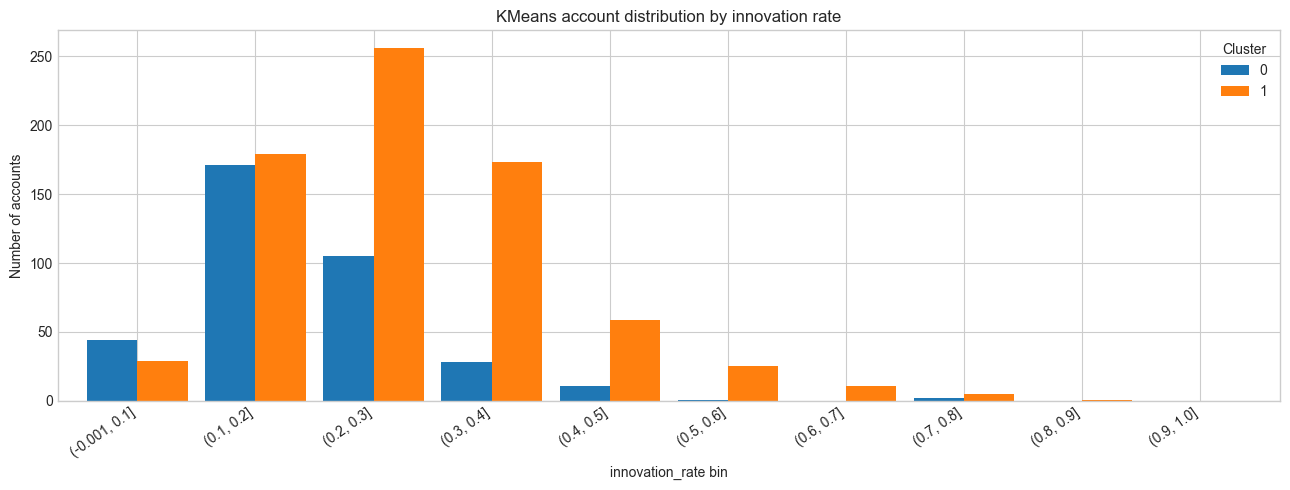

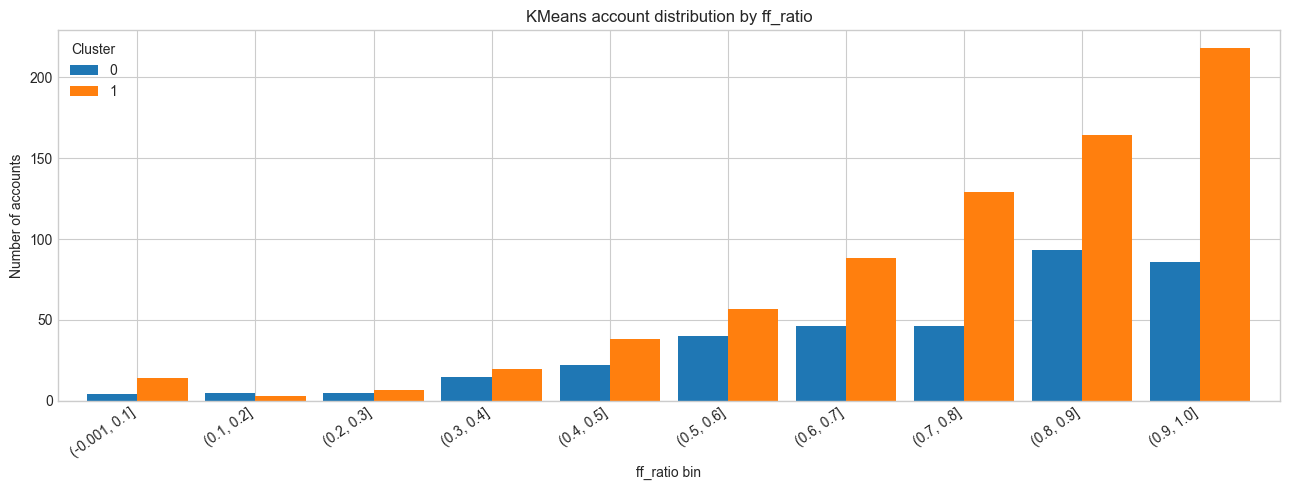

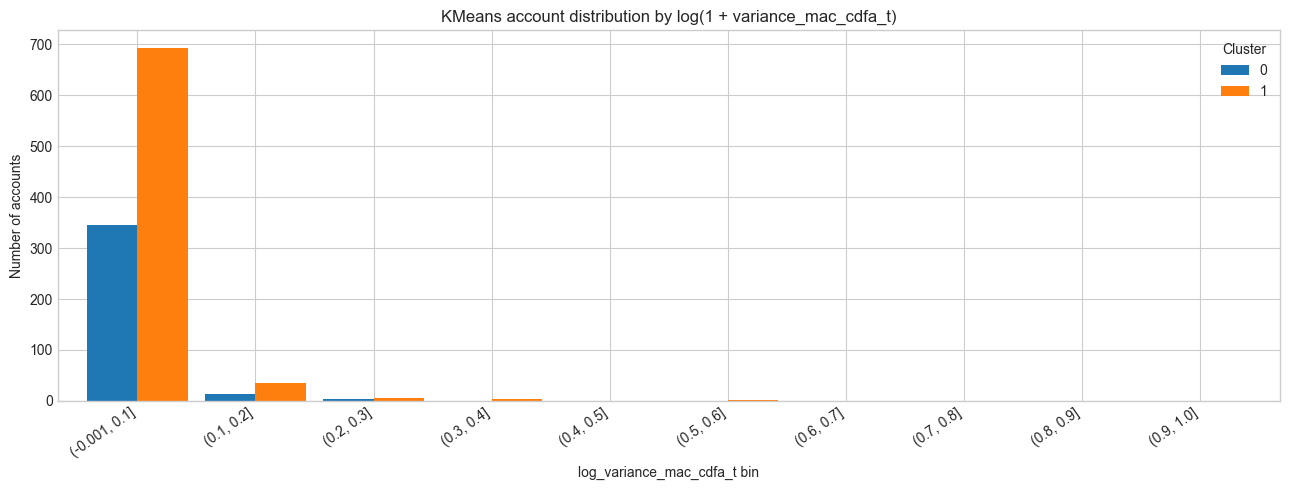

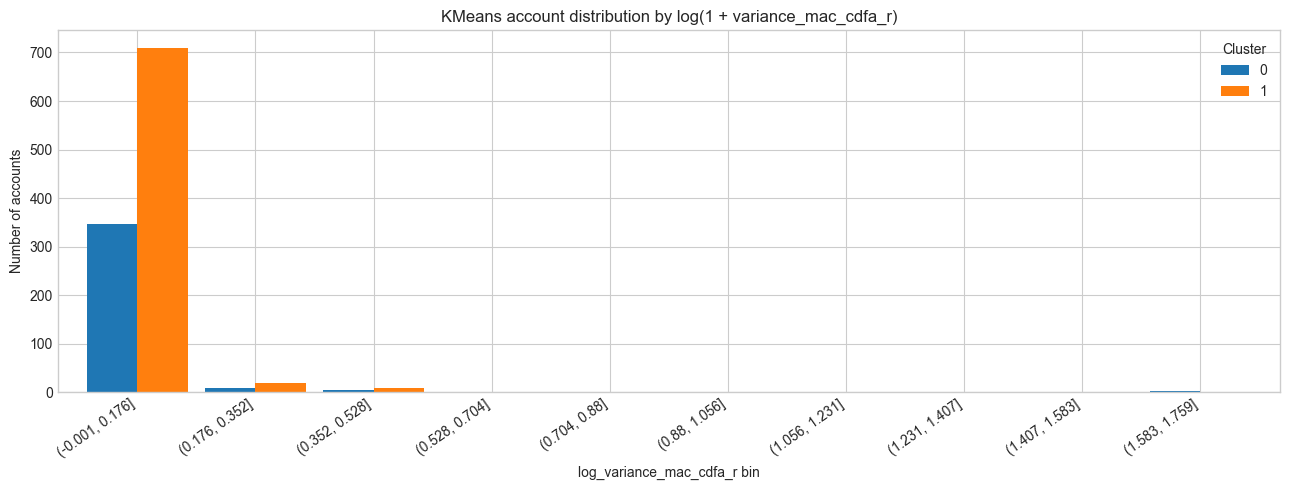

Sampled accounts per cluster:


,account,cluster
0,alsprinting,0
1,bigwoo,0
2,cutiemania,0
3,elizabeth302,0
4,hsgrs,0
5,lismarcarolina,0
6,mcmira1,0
7,teslim,0
8,cryptowiththomas,1
9,eliskaplitzova,1



Cluster 0 (8 shown):
alsprinting, bigwoo, cutiemania, elizabeth302, hsgrs, lismarcarolina, mcmira1, teslim

Cluster 1 (8 shown):
cryptowiththomas, eliskaplitzova, ernestajao, fahimsaeed, halim09, jayjml, pescalante63, suaychanthavong


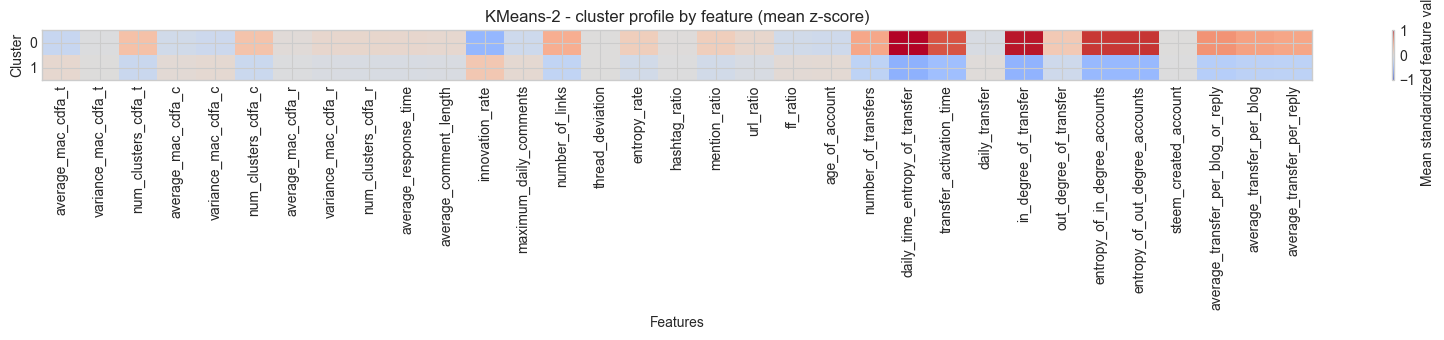

In [29]:
# Reuse X_df / X_scaled from previous cell if available, otherwise rebuild.
if 'X_df' not in globals() or 'X_scaled' not in globals():
    features_path = '../data/steem_collection/features.csv'
    features_df = pd.read_csv(features_path)
    X_df = features_df.select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    if X_df.empty:
        raise ValueError('No numeric features found in features.csv for clustering plots.')
    X = X_df.to_numpy(dtype=float)
    X_scaled = StandardScaler().fit_transform(X)

feature_names = X_df.columns.tolist()
X_z = pd.DataFrame(X_scaled, columns=feature_names)

# KMeans-only feature profile (first step).
kmeans = KMeans(n_clusters=2, random_state=42, n_init=20)
kmeans.fit(X_scaled)

# Account names are in the first column of features.csv
account_col = features_df.columns[0]  # first column = account name
account_names = features_df[account_col].astype(str).reset_index(drop=True)

cluster_accounts = pd.DataFrame({
    'account': account_names,
    'cluster': kmeans.labels_
})

# Base frame used for per-cluster metric-distribution charts
plot_df = pd.DataFrame({
    'account': account_names,
    'cluster': kmeans.labels_,
    'innovation_rate': pd.to_numeric(features_df['innovation_rate'], errors='coerce'),
    'ff_ratio': pd.to_numeric(features_df['ff_ratio'], errors='coerce'),
    'variance_mac_cdfa_t': pd.to_numeric(features_df['variance_mac_cdfa_t'], errors='coerce'),
    'variance_mac_cdfa_r': pd.to_numeric(features_df['variance_mac_cdfa_r'], errors='coerce')
})

def plot_cluster_distribution(df, value_col, title, bins=None, y_label='Number of accounts'):
    local = df[['cluster', value_col]].copy().dropna()
    if local.empty:
        print(f'{title}: no valid data to plot.')
        return

    col_min, col_max = local[value_col].min(), local[value_col].max()
    if bins is None:
        if col_min >= 0 and col_max <= 1:
            bins = np.linspace(0, 1, 11)  # 10 bins for ratio-like metrics
        elif col_min == col_max:
            bins = np.linspace(col_min - 0.5, col_max + 0.5, 3)
        else:
            bins = np.linspace(col_min, col_max, 11)

    binned_col = f'{value_col}_bin'
    local[binned_col] = pd.cut(local[value_col], bins=bins, include_lowest=True)

    dist = (
        local.groupby([binned_col, 'cluster'], observed=False)
        .size()
        .unstack(fill_value=0)
    )

    ax = dist.plot(kind='bar', figsize=(13, 5), width=0.85)
    ax.set_title(title)
    ax.set_xlabel(f'{value_col} bin')
    ax.set_ylabel(y_label)
    ax.legend(title='Cluster')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()

# Existing chart: innovation rate distribution by cluster
plot_cluster_distribution(
    plot_df,
    'innovation_rate',
    'KMeans account distribution by innovation rate'
 )

# Additional chart 1: ff_ratio distribution by cluster
plot_cluster_distribution(
    plot_df,
    'ff_ratio',
    'KMeans account distribution by ff_ratio'
 )

# Additional chart 2: log-scaled variance_mac_cdfa_t distribution by cluster
plot_df['log_variance_mac_cdfa_t'] = np.log1p(plot_df['variance_mac_cdfa_t'].clip(lower=0))
plot_cluster_distribution(
    plot_df,
    'log_variance_mac_cdfa_t',
    'KMeans account distribution by log(1 + variance_mac_cdfa_t)'
 )

# Additional chart 3: log-scaled variance_mac_cdfa_r distribution by cluster
plot_df['log_variance_mac_cdfa_r'] = np.log1p(plot_df['variance_mac_cdfa_r'].clip(lower=0))
plot_cluster_distribution(
    plot_df,
    'log_variance_mac_cdfa_r',
    'KMeans account distribution by log(1 + variance_mac_cdfa_r)'
 )

# Sample N accounts from each cluster
N = 8
sampled_accounts = pd.concat(
    [
        group.sample(n=min(N, len(group)), random_state=42)
        for _, group in cluster_accounts.groupby('cluster')
    ],
    ignore_index=True
)
sampled_accounts = sampled_accounts.sort_values(['cluster', 'account']).reset_index(drop=True)

print('Sampled accounts per cluster:')
display(sampled_accounts)

# Optional: print as plain lists
for c, g in sampled_accounts.groupby('cluster'):
    print(f'\nCluster {c} ({len(g)} shown):')
    print(', '.join(g['account'].tolist()))

labels_series = pd.Series(kmeans.labels_, name='segment').astype(str)
profile = X_z.groupby(labels_series).mean().sort_index()

if profile.empty:
    print('KMeans-2: no clusters available for profiling.')
else:
    max_abs = float(np.abs(profile.values).max())
    norm = TwoSlopeNorm(vmin=-max_abs, vcenter=0.0, vmax=max_abs)

    fig_w = max(12, 0.5 * len(feature_names))
    fig_h = max(3.5, 1.2 * len(profile.index))
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    im = ax.imshow(profile.values, aspect='auto', cmap='coolwarm', norm=norm)

    ax.set_title('KMeans-2 - cluster profile by feature (mean z-score)')
    ax.set_xlabel('Features')
    ax.set_ylabel('Cluster')

    ax.set_xticks(np.arange(len(feature_names)))
    ax.set_xticklabels(feature_names, rotation=90)
    ax.set_yticks(np.arange(len(profile.index)))
    ax.set_yticklabels(profile.index.tolist())

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label('Mean standardized feature value (z-score)')

    plt.tight_layout()
    plt.show()

Top 15 features contributing to KMeans separation:


d:\FYP\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
d:\FYP\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,feature,anova_f_score
0,daily_time_entropy_of_transfer,1128.669294
1,in_degree_of_transfer,982.997557
2,entropy_of_out_degree_accounts,741.921250
3,entropy_of_in_degree_accounts,728.037253
4,transfer_activation_time,508.115388
5,average_transfer_per_blog_or_reply,180.693165
6,average_transfer_per_blog,129.047297
7,innovation_rate,123.493907
8,average_transfer_per_reply,113.873127
9,number_of_transfers,111.018393


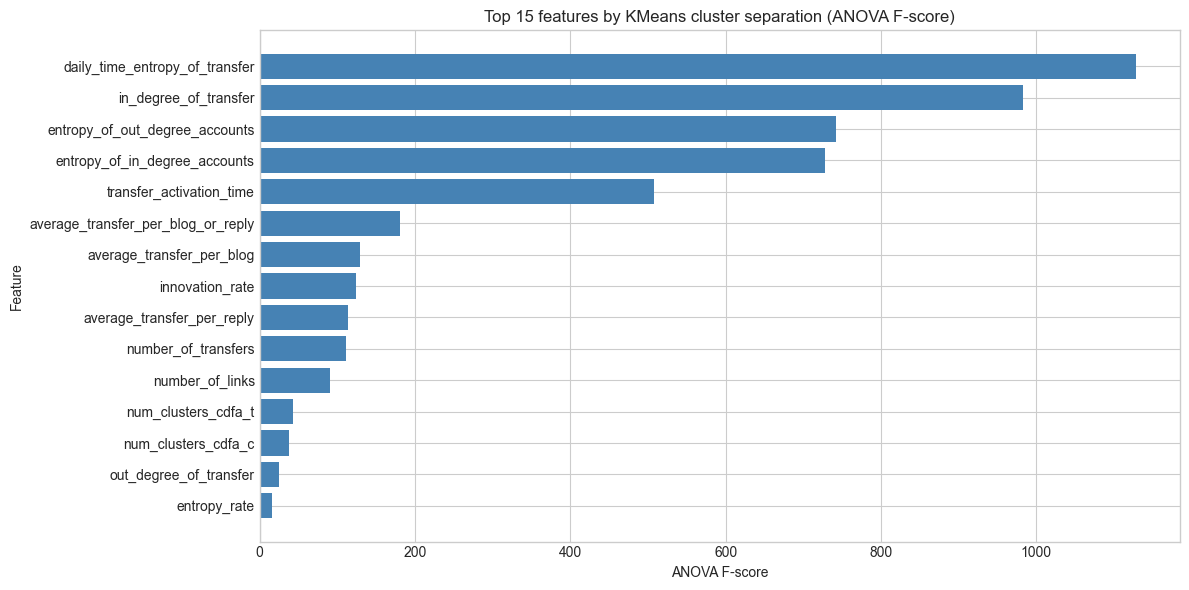

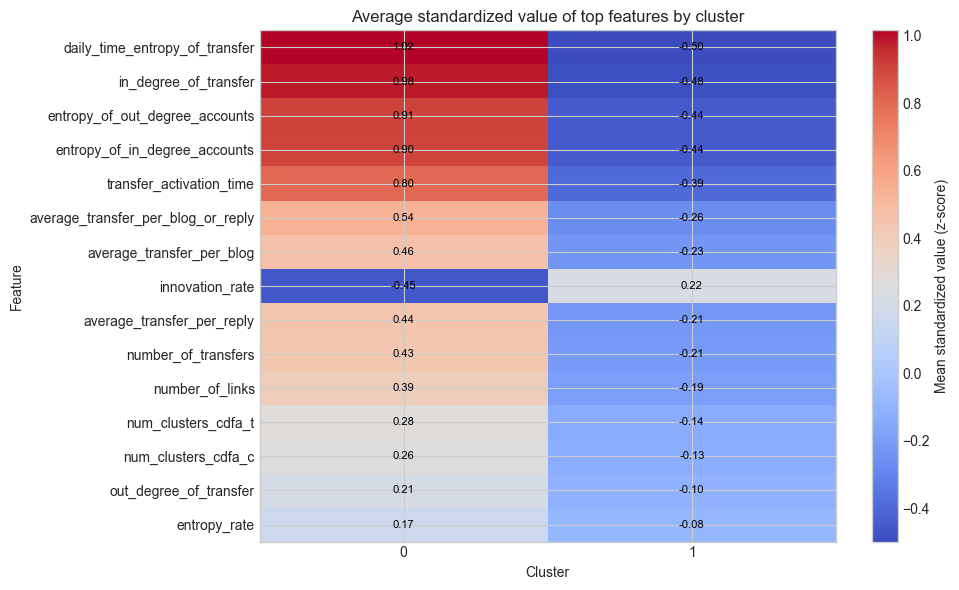

In [30]:
## Feature Importance Analysis
# This section quantifies which features most strongly separate the KMeans clusters.

# Method:
# - fit KMeans on the standardized feature matrix
# - compute an ANOVA F-score for each feature with cluster label as the target
# - rank features by separation strength and visualize the top contributors

from sklearn.feature_selection import f_classif

# Reuse/refresh the clustering inputs if they are not already in memory
if 'X_df' not in globals() or 'X_scaled' not in globals() or 'kmeans' not in globals():
    features_path = '../data/steem_collection/features.csv'
    features_df = pd.read_csv(features_path)
    X_df = features_df.select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    if X_df.empty:
        raise ValueError('No numeric features found in features.csv for feature importance analysis.')
    X = X_df.to_numpy(dtype=float)
    X_scaled = StandardScaler().fit_transform(X)
    kmeans = KMeans(n_clusters=2, random_state=42, n_init=20)
    kmeans.fit(X_scaled)

feature_names = X_df.columns.tolist()
X_for_importance = pd.DataFrame(X_scaled, columns=feature_names)

f_scores, _ = f_classif(X_for_importance, kmeans.labels_)
importance_df = pd.DataFrame({
    'feature': feature_names,
    'anova_f_score': f_scores
}).sort_values('anova_f_score', ascending=False).reset_index(drop=True)

# Show the top-ranked variables for interpretation
N_display = min(15, len(importance_df))
top_features = importance_df.head(N_display).copy()
print(f'Top {N_display} features contributing to KMeans separation:')
display(top_features)

fig, ax = plt.subplots(figsize=(12, max(6, 0.35 * N_display)))
ax.barh(top_features['feature'][::-1], top_features['anova_f_score'][::-1], color='steelblue')
ax.set_title(f'Top {N_display} features by KMeans cluster separation (ANOVA F-score)')
ax.set_xlabel('ANOVA F-score')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

# Cluster-wise mean standardized values for the most important features
important_names = top_features['feature'].tolist()
cluster_profile = X_for_importance[important_names].copy()
cluster_profile['cluster'] = kmeans.labels_.astype(int)
cluster_profile = cluster_profile.groupby('cluster').mean().T

fig, ax = plt.subplots(figsize=(max(10, 0.5 * len(cluster_profile.columns)), 6))
img = ax.imshow(cluster_profile.to_numpy(), cmap='coolwarm', aspect='auto')
ax.set_title('Average standardized value of top features by cluster')
ax.set_xlabel('Cluster')
ax.set_ylabel('Feature')
ax.set_xticks(range(len(cluster_profile.columns)))
ax.set_xticklabels(cluster_profile.columns)
ax.set_yticks(range(len(cluster_profile.index)))
ax.set_yticklabels(cluster_profile.index)
for i in range(len(cluster_profile.index)):
    for j in range(len(cluster_profile.columns)):
        ax.text(j, i, f'{cluster_profile.to_numpy()[i, j]:.2f}', ha='center', va='center', color='black', fontsize=8)
fig.colorbar(img, ax=ax, label='Mean standardized value (z-score)')
plt.tight_layout()
plt.show()
